In [12]:
# Restart the kernel

import IPython
IPython.Application.instance().kernel.do_shutdown(True)

{'status': 'ok', 'restart': True}

In [1]:
!pip install -q --upgrade transformers==4.56.2 diffusers==0.32.2 accelerate

In [2]:
# Log in to Hugging Face
from huggingface_hub import login
from google.colab import userdata

hf_token = userdata.get('HF_TOKEN')
if hf_token and hf_token.startswith("hf_"):
  print("HF key looks good so far")
else:
  print("HF key is not set - please click the key in the left sidebar")
login(hf_token, add_to_git_credential=True)

# Check Google Colab GPU

gpu_info = !nvidia-smi
gpu_info = '\n'.join(gpu_info)
if gpu_info.find('failed') >= 0:
  print('Not connected to a GPU')
else:
  print(gpu_info)
  if gpu_info.find('Tesla T4') >= 0:
    print("Success - Connected to a T4")
  else:
    print("NOT CONNECTED TO A T4")

HF key looks good so far
Sat Nov  7 16:05:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------

In [3]:
import os
import json
from openai import OpenAI
from google import genai
from IPython.display import display
from diffusers import DiffusionPipeline
from diffusers import AutoPipelineForText2Image
import tempfile
import gradio as gr
import base64
import sqlite3
from io import BytesIO
import torch

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [4]:

username=userdata.get('APP_USER')
password=userdata.get('APP_PASSWORD')
google_api_key =userdata.get('GOOGLE_API_KEY')
if google_api_key and google_api_key.startswith('AQ'):
    print(f"Google API Key exists")
else:
    print("Google API Key not set")

gemini_url = "https://generativelanguage.googleapis.com/v1beta/openai/"
gemini = OpenAI(api_key=google_api_key, base_url=gemini_url)


Google API Key exists


In [5]:
MODEL='gemini-2.5-flash'
#AUDIO client
audio = genai.Client(api_key=google_api_key)

system_message="""
you are a helpful assistant for an airline called flightAI.
give short,courteous answer ,no  more than 1 sentence.
always be accurate . if don't know what to answer say i don't know
"""
# with database
DB = "prices.db"

with sqlite3.connect(DB) as conn:
    cursor = conn.cursor()
    cursor.execute('CREATE TABLE IF NOT EXISTS prices (city TEXT PRIMARY KEY, price REAL)')
    conn.commit()

def set_ticket_price(city, price):
    with sqlite3.connect(DB) as conn:
        cursor = conn.cursor()
        cursor.execute('INSERT INTO prices (city, price) VALUES (?, ?) ON CONFLICT(city) DO UPDATE SET price = ?', (city.lower(), price, price))
        conn.commit()

set_ticket_price("NewYork", 577)
set_ticket_price("London", 500)
set_ticket_price("Paris", 1200)

In [6]:

#TOOL1
def get_ticket_price(city):
    print(f"DATABASE TOOL CALLED: Getting price for {city}", flush=True)
    with sqlite3.connect(DB) as conn:
        cursor = conn.cursor()
        cursor.execute('SELECT price FROM prices WHERE city = ?', (city.lower(),))
        result = cursor.fetchone()
        return f"Ticket price to {city} is ${result[0]}" if result else "No price data available for this city"

#describe the function to the model
price_function = {
    "name": "get_ticket_price",
    "description": "Get the price of a return ticket to the destination city.",
    "parameters": {
        "type": "object",
        "properties": {
            "destination_city": {
                "type": "string",
                "description": "The city that the customer wants to travel to",
            },
        },
        "required": ["destination_city"],
        "additionalProperties": False
    }
}

# And this is included in a list of tools:

tools = [{"type": "function", "function": price_function}]


def handle_tool_calls_and_return_cities(message):
    responses = []
    cities= []
    for tool_call in message.tool_calls:
        if tool_call.function.name == "get_ticket_price":
           arguments = json.loads(tool_call.function.arguments)
           city = arguments.get('destination_city')
           cities.append(city)
           price_details = get_ticket_price(city)
           responses.append({
               "role": "tool",
               "content": price_details,
               "tool_call_id": tool_call.id
            })
    return responses,cities

In [9]:
get_ticket_price('paris')

DATABASE TOOL CALLED: Getting price for paris


'Ticket price to paris is $1200.0'

In [1]:
def artist(city):
    base = DiffusionPipeline.from_pretrained("stabilityai/stable-diffusion-xl-base-1.0", torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    base.to("cuda")
    prompt = (f"An image representing a vacation in {city}, showing tourist spots and everything unique about {city}, in a vibrant pop-art style")

    # run both experts
    image = base(
        prompt=prompt,
        num_inference_steps=25,
        height=512,
        width=512
    ).images[0]


    return(image)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/737 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/565 [00:00<?, ?B/s]

... (12 outputs left out)

vae_1_0/diffusion_pytorch_model.fp16.saf(…):   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


  0%|          | 0/25 [00:00<?, ?it/s]

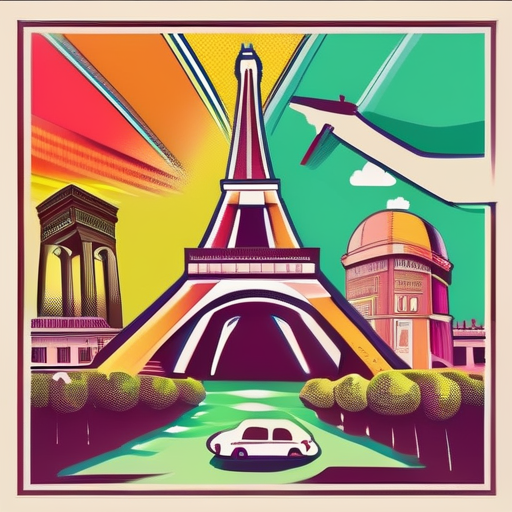

In [9]:
artist('paris')

In [8]:
def talker(message):
    response = audio.interactions.create(
        model="gemini-3.8-flash-tts",
        input=[{
            "type": "user_input",
            "content": [{
                "type": "text",
                "text": message
            }]
        }],
        response_format={"type": "audio"},
        generation_config={
            "speech_config": [
                {"voice": "Kore"}
            ]
        }
    )
    audio_data = base64.b64decode( response.output_audio.data)
    with tempfile.NamedTemporaryFile(
        suffix=".wav", delete=False
    ) as audio_file:
        audio_file.write(audio_data)
        return audio_file.name


In [9]:

def chat (history):
     history = [{"role":h["role"], "content":h["content"]} for h in history]
     messages = [{"role": "system", "content": system_message}] + history
     response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)
     cities=[]
     image=None
     while response.choices[0].finish_reason=="tool_calls":
       message = response.choices[0].message
       responses, cities = handle_tool_calls_and_return_cities(message)
       messages.append(message)
       messages.extend(responses)
       response = gemini.chat.completions.create(model=MODEL, messages=messages)
     reply=response.choices[0].message.content

     if not reply:
        reply = "Sorry, I couldn't generate a response."
     history+=[{"role":"assistant","content":reply}]
     voice=talker(reply)
    # Generate image only if a city was requested
     if cities:
        try:
            image = artist(cities[0])

        except Exception as e:
            print("Image generation error:", e)

     return history, voice, image


In [10]:
def put_message_in_chatbot(message, history):
        return "", history + [{"role":"user", "content":message}]


In [11]:

# UI definition

with gr.Blocks() as ui:
    with gr.Row():
        chatbot = gr.Chatbot(height=500)
        image_output = gr.Image(height=500, interactive=False)
    with gr.Row():
        audio_output = gr.Audio(autoplay=True)
    with gr.Row():
        message = gr.Textbox(label="Chat with our AI Assistant:")

# Hooking up events to callbacks

    message.submit(put_message_in_chatbot, inputs=[message, chatbot], outputs=[message, chatbot]).then(
        chat, inputs=chatbot, outputs=[chatbot, audio_output, image_output]
    )

ui.launch(inbrowser=True, auth=(username,password))

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://70daab8f543fc0beae.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
